# Conditionals and Iteration

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
# warnings.simplefilter(action='ignore', category=np.VisibleDeprecationWarning)

In [2]:
# polars
import polars as pl
from IPython.display import display
import numpy as np

def _append(base, extra):
    """Append a value or a Series onto a Series."""
    extra_s = extra if isinstance(extra, pl.Series) else pl.Series([extra])
    if base.len() == 0:
        return extra_s
    if base.dtype != extra_s.dtype:
        try:
            extra_s = extra_s.cast(base.dtype, strict=False)
        except Exception:
            base = base.cast(extra_s.dtype, strict=False)
    return pl.concat([base, extra_s])


## Appending Arrays

In [3]:
# datascience
first = np.arange(4)
second = np.arange(10, 17)

In [4]:
# polars
first_pl = pl.int_range(4, eager=True)
second_pl = pl.int_range(10, 17, eager=True)

In [5]:
# datascience
first

array([0, 1, 2, 3])

In [6]:
# polars
first_pl

literal
i64
0
1
2
3


In [7]:
# datascience
np.append(first, 6)

array([0, 1, 2, 3, 6])

In [8]:
# polars
_append(first_pl, 6)

literal
i64
0
1
2
3
6


In [9]:
# datascience
first

array([0, 1, 2, 3])

In [10]:
# polars
first_pl

literal
i64
0
1
2
3


In [11]:
# datascience
# how do we change `first`?
first = np.append(first, 6)

In [12]:
# polars
# how do we change `first`?
first_pl = _append(first_pl, 6)

In [13]:
# datascience
np.append(first, second)

array([ 0,  1,  2,  3,  6, 10, 11, 12, 13, 14, 15, 16])

In [14]:
# polars
_append(first_pl, second_pl)

literal
i64
0
1
2
3
6
…
12
13
14


In [15]:
# datascience
first

array([0, 1, 2, 3, 6])

In [16]:
# polars
first_pl

literal
i64
0
1
2
3
6


In [17]:
# datascience
second

array([10, 11, 12, 13, 14, 15, 16])

In [18]:
# polars
second_pl

literal
i64
10
11
12
13
14
15
16


## Comparison ##

In [19]:
3 > 1

True

In [20]:
type(3 > 1)

<class 'bool'>

In [21]:
True

True

In [22]:
true

NameError: name 'true' is not defined

(We see that capitalization matters.)

In [23]:
3 = 3

SyntaxError: cannot assign to literal here. Maybe you meant '==' instead of '='? (<unknown>, line 1)

In [24]:
3 == 3.0

True

In [25]:
10 != 2

True

In [26]:
x = 14
y = 3

In [27]:
x > 15

False

In [28]:
12 < x

True

In [29]:
x < 20

True

In [30]:
12 < x < 20

True

In [31]:
10 < x-y < 13

True

In [32]:
x > 13 and y < 3.14159

True

(The comparison `12 < x < 20` is equivalent to `12 < x and x < 20`.)

## Comparisons with arrays

In [33]:
# datascience
pets = make_array('cat', 'cat', 'dog', 'cat', 'dog', 'rabbit')

In [34]:
# polars
pets_pl = pl.Series("values", ['cat', 'cat', 'dog', 'cat', 'dog', 'rabbit'])

In [35]:
# datascience
pets == 'cat'

array([ True,  True, False,  True, False, False], dtype=bool)

In [36]:
# polars
pets_pl == 'cat'

values
bool
true
true
false
true
false
false


In [37]:
1 + 1 + 0 + 1 + 0 + 0

3

In [38]:
# datascience
sum(make_array(True, True, False, True, False, False))

3

In [39]:
# polars
sum(pl.Series("values", [True, True, False, True, False, False]))

3

In [40]:
# datascience
sum(pets == 'cat')

3

In [41]:
# polars
sum(pets_pl == 'cat')

3

In [42]:
# datascience
np.count_nonzero(pets == 'cat')

3

In [43]:
# polars
(lambda _s: _s.sum() if _s.dtype == pl.Boolean else (_s != 0).sum())(pets_pl == 'cat')

3

In [44]:
# datascience
xs = np.arange(20, 31)

In [45]:
# polars
xs_pl = pl.int_range(20, 31, eager=True)

In [46]:
# datascience
xs

array([20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30])

In [47]:
# polars
xs_pl

literal
i64
20
21
22
23
24
…
26
27
28


In [48]:
# datascience
xs > 28

array([False, False, False, False, False, False, False, False, False,
        True,  True], dtype=bool)

In [49]:
# polars
xs_pl > 28

literal
bool
false
false
false
false
false
…
false
false
false


In [50]:
# datascience
sum(xs > 28)

2

In [51]:
# polars
sum(xs_pl > 28)

2

## Conditional Statements

In [52]:
age = 20

In [53]:
if age >= 18:
    print('You can legally vote.')
else:
    if age >= 16:
        print("You can't vote just yet, but you can pre-register!")
    else:
        print("You can't vote just yet.")

You can legally vote.


In [54]:
if age >= 18:
    print('You can legally vote.')
if age >= 16:
    print("You can't vote just yet, but you can pre-register!")
else:
    print("You can't vote just yet.")

You can legally vote.
You can't vote just yet, but you can pre-register!


In [55]:
def vote(age):
    if age >= 18:
        return 'You can legally vote.'
    elif age >= 16:
        return "You can't vote just yet, but you can pre-register!"
    else:
        return "You can't vote just yet."

In [56]:
vote(3)

"You can't vote just yet."

In [57]:
vote(17)

"You can't vote just yet, but you can pre-register!"

In [58]:
vote(25)

'You can legally vote.'

In [59]:
# datascience
def rights(age):
	my_rights = make_array()
	if age >= 16:
		my_rights = np.append(my_rights, 'register to vote')
	if age >= 18:
		my_rights = np.append(my_rights, 'vote')
	return my_rights

In [60]:
# polars
def rights_pl(age):
	my_rights = pl.Series("values", [], dtype=pl.String)
	if age >= 16:
		my_rights = _append(my_rights, 'register to vote')
	if age >= 18:
		my_rights = _append(my_rights, 'vote')
	return my_rights

In [61]:
# datascience
rights(3)

array([], dtype=float64)

In [62]:
# polars
rights_pl(3)

values
str


In [63]:
# datascience
rights(17)

array(['register to vote'],
      dtype='<U32')

In [64]:
# polars
rights_pl(17)

""
str
"""register to vote"""


In [65]:
# datascience
rights(25)

array(['register to vote', 'vote'],
      dtype='<U32')

In [66]:
# polars
rights_pl(25)

""
str
"""register to vote"""
"""vote"""


In [67]:
# datascience
trip = Table().read_table('trip.csv').sort('Zip Code')
trip.show(5)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
901821,609,8/24/2015 0:11,Powell at Post (Union Square),71,8/24/2015 0:21,Grant Avenue at Columbus Avenue,73,611,Customer,0
901820,1063,8/23/2015 23:44,Embarcadero at Sansome,60,8/24/2015 0:02,Powell at Post (Union Square),71,383,Customer,0
901713,1550,8/23/2015 17:20,Post at Kearny,47,8/23/2015 17:45,Market at 10th,67,623,Customer,0
878924,11785,8/6/2015 16:02,Civic Center BART (7th at Market),72,8/6/2015 19:18,Embarcadero at Sansome,60,625,Customer,0
878920,138,8/6/2015 15:58,Civic Center BART (7th at Market),72,8/6/2015 16:00,Civic Center BART (7th at Market),72,67,Customer,0


In [68]:
# polars
trip_pl = pl.read_csv('trip.csv', schema_overrides={"Zip Code": pl.String}).sort('Zip Code')
trip_pl.head(5)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
i64,i64,str,str,i64,str,str,i64,i64,str,str
912455,2092,"""8/31/2015 12:40""","""SJSU 4th at San Carlos""",12,"""8/31/2015 13:14""","""SJSU 4th at San Carlos""",12,186,"""Customer""",null
910752,586,"""8/29/2015 9:01""","""Harry Bridges Plaza (Ferry Bui…",50,"""8/29/2015 9:10""","""Powell at Post (Union Square)""",71,260,"""Customer""",null
910713,4323,"""8/29/2015 7:26""","""Embarcadero at Vallejo""",48,"""8/29/2015 8:38""","""Embarcadero at Vallejo""",48,355,"""Customer""",null
910711,537,"""8/29/2015 6:48""","""Post at Kearny""",47,"""8/29/2015 6:57""","""Harry Bridges Plaza (Ferry Bui…",50,189,"""Customer""",null
901105,684,"""8/22/2015 12:06""","""Steuart at Market""",74,"""8/22/2015 12:18""","""Market at 4th""",76,382,"""Customer""",null


In [69]:
# datascience
def trip_kind(start, end):
    if start == end:
        return 'round trip'
    else:
        return 'one way'

# trip.show(5)

kinds = trip.apply(trip_kind, 'Start Station', 'End Station')
with_kinds = trip.with_column('Trip Kind', kinds)
with_kinds.show(5)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code,Trip Kind
901821,609,8/24/2015 0:11,Powell at Post (Union Square),71,8/24/2015 0:21,Grant Avenue at Columbus Avenue,73,611,Customer,0,one way
901820,1063,8/23/2015 23:44,Embarcadero at Sansome,60,8/24/2015 0:02,Powell at Post (Union Square),71,383,Customer,0,one way
901713,1550,8/23/2015 17:20,Post at Kearny,47,8/23/2015 17:45,Market at 10th,67,623,Customer,0,one way
878924,11785,8/6/2015 16:02,Civic Center BART (7th at Market),72,8/6/2015 19:18,Embarcadero at Sansome,60,625,Customer,0,one way
878920,138,8/6/2015 15:58,Civic Center BART (7th at Market),72,8/6/2015 16:00,Civic Center BART (7th at Market),72,67,Customer,0,round trip


In [70]:
# polars
def trip_kind_pl(start, end):
    if start == end:
        return 'round trip'
    else:
        return 'one way'

# trip.show(5)

kinds_pl = trip_pl.select(pl.struct(['Start Station', 'End Station']).map_elements(lambda s: trip_kind_pl(s['Start Station'], s['End Station']), return_dtype=pl.String)).to_series()
with_kinds_pl = trip_pl.with_columns(pl.Series('Trip Kind', kinds_pl))
with_kinds_pl.head(5)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code,Trip Kind
i64,i64,str,str,i64,str,str,i64,i64,str,str,str
912455,2092,"""8/31/2015 12:40""","""SJSU 4th at San Carlos""",12,"""8/31/2015 13:14""","""SJSU 4th at San Carlos""",12,186,"""Customer""",null,"""round trip"""
910752,586,"""8/29/2015 9:01""","""Harry Bridges Plaza (Ferry Bui…",50,"""8/29/2015 9:10""","""Powell at Post (Union Square)""",71,260,"""Customer""",null,"""one way"""
910713,4323,"""8/29/2015 7:26""","""Embarcadero at Vallejo""",48,"""8/29/2015 8:38""","""Embarcadero at Vallejo""",48,355,"""Customer""",null,"""round trip"""
910711,537,"""8/29/2015 6:48""","""Post at Kearny""",47,"""8/29/2015 6:57""","""Harry Bridges Plaza (Ferry Bui…",50,189,"""Customer""",null,"""one way"""
901105,684,"""8/22/2015 12:06""","""Steuart at Market""",74,"""8/22/2015 12:18""","""Market at 4th""",76,382,"""Customer""",null,"""one way"""


In [71]:
# datascience
# recall pivot! what will we see?
with_kinds.where('Duration', are.below(600)).pivot('Trip Kind', 'Start Station')

Start Station,one way,round trip
2nd at Folsom,6821,25
2nd at South Park,6484,98
2nd at Townsend,9513,83
5th at Howard,5752,36
Adobe on Almaden,439,8
Arena Green / SAP Center,382,18
Beale at Market,5750,32
Broadway St at Battery St,4482,59
California Ave Caltrain Station,39,12
Castro Street and El Camino Real,1005,10


In [72]:
# polars
# recall pivot! what will we see?
(lambda _p: _p.select(['Start Station'] + sorted([c for c in _p.columns if c != 'Start Station'], key=str)))(with_kinds_pl.filter(pl.col('Duration') < 600).pivot('Trip Kind', index='Start Station', values='Trip Kind', aggregate_function='len').sort('Start Station'))

Start Station,one way,round trip
str,u32,u32
"""2nd at Folsom""",6821,25
"""2nd at South Park""",6484,98
"""2nd at Townsend""",9513,83
"""5th at Howard""",5752,36
"""Adobe on Almaden""",439,8
…,…,…
"""Temporary Transbay Terminal (H…",9585,52
"""Townsend at 7th""",8073,68
"""University and Emerson""",60,18


## Simulation

Let's play a game: we each roll a die. 

If my number is bigger: you pay me a dollar.

If they're the same: we do nothing.

If your number is bigger: I pay you a dollar.

Steps:
1. Find a way to simulate two dice rolls.
2. Compute how much money we win/lose based on the result.
3. Do steps 1 and 2 10,000 times.

### Conditional Statements

In [73]:
# Work in progress
def one_round(my_roll, your_roll):
    if my_roll > your_roll:
        return 1

In [74]:
one_round(4, 3)

1

In [75]:
one_round(2, 6)

In [76]:
def one_round(my_roll, your_roll):
    if my_roll > your_roll:
        return 1
    elif your_roll > my_roll:
        return -1
    elif your_roll == my_roll:
        return 0

In [77]:
one_round(1, 1)

0

In [78]:
one_round(6, 5)

1

In [79]:
one_round(-7, -1)

-1

### Random Selection

In [80]:
# datascience
mornings = make_array('wake up', 'sleep in')

In [81]:
# polars
mornings_pl = pl.Series("values", ['wake up', 'sleep in'])

In [82]:
# datascience
np.random.choice(mornings)

'wake up'

In [83]:
# polars
(mornings_pl).sample(1).item()

'sleep in'

In [84]:
# datascience
np.random.choice(mornings)

'sleep in'

In [85]:
# polars
(mornings_pl).sample(1).item()

'wake up'

In [86]:
# datascience
np.random.choice(mornings)

'wake up'

In [87]:
# polars
(mornings_pl).sample(1).item()

'wake up'

We can also pass an argument that specifies how many times to make a random choice:

In [88]:
# datascience
np.random.choice(mornings, 7)

array(['sleep in', 'wake up', 'sleep in', 'wake up', 'wake up', 'wake up',
       'wake up'],
      dtype='<U8')

In [89]:
# polars
(mornings_pl).sample(7, with_replacement=True)

values
str
"""sleep in"""
"""wake up"""
"""sleep in"""
"""sleep in"""
"""wake up"""
"""wake up"""
"""wake up"""


In [90]:
# datascience
sum(np.random.choice(mornings, 7) == 'wake up')

4

In [91]:
# polars
sum((mornings_pl).sample(7, with_replacement=True) == 'wake up')

2

In [92]:
# datascience
sum(np.random.choice(mornings, 7) == 'sleep in')

5

In [93]:
# polars
sum((mornings_pl).sample(7, with_replacement=True) == 'sleep in')

3

^ Why don't these (always) sum to 7?

In [94]:
# datascience
morning_week = np.random.choice(mornings, 7)
morning_week

array(['sleep in', 'sleep in', 'wake up', 'sleep in', 'sleep in',
       'wake up', 'sleep in'],
      dtype='<U8')

In [95]:
# polars
morning_week_pl = (mornings_pl).sample(7, with_replacement=True)
morning_week_pl

values
str
"""wake up"""
"""sleep in"""
"""wake up"""
"""wake up"""
"""wake up"""
"""wake up"""
"""wake up"""


In [96]:
# datascience
sum(morning_week == 'wake up')

2

In [97]:
# polars
sum(morning_week_pl == 'wake up')

6

In [98]:
# datascience
sum(morning_week == 'sleep in')

5

In [99]:
# polars
sum(morning_week_pl == 'sleep in')

1

### Simulating the roll of a die

In [100]:
# datascience
die_faces = np.arange(1, 7)

In [101]:
# polars
die_faces_pl = pl.int_range(1, 7, eager=True)

In [102]:
# datascience
np.random.choice(die_faces)

4

In [103]:
# polars
(die_faces_pl).sample(1).item()

5

In [104]:
# datascience
def simulate_one_round():
    my_roll = np.random.choice(die_faces)
    your_roll = np.random.choice(die_faces)
    return one_round(my_roll, your_roll)

In [105]:
# polars
def simulate_one_round_pl():
    my_roll = (die_faces_pl).sample(1).item()
    your_roll = (die_faces_pl).sample(1).item()
    return one_round(my_roll, your_roll)

In [106]:
# datascience
simulate_one_round()

1

In [107]:
# polars
simulate_one_round_pl()

1

### Repeated Betting ###

In [108]:
# datascience
results = make_array()

In [109]:
# polars
results_pl = pl.Series("values", [], dtype=pl.Float64)

In [110]:
# datascience
results = np.append(results, simulate_one_round())
results

array([ 1.])

In [111]:
# polars
results_pl = _append(results_pl, simulate_one_round_pl())
results_pl

""
i64
1


In [112]:
# datascience
results = np.append(results, simulate_one_round())
results

array([ 1.,  0.])

In [113]:
# polars
results_pl = _append(results_pl, simulate_one_round_pl())
results_pl

""
i64
1
1


## `For` Statements

In [114]:
# datascience
for pet in make_array('cat', 'dog', 'rabbit'):
    print('I love my ' + pet)

I love my cat
I love my dog
I love my rabbit


In [115]:
# polars
for pet in pl.Series("values", ['cat', 'dog', 'rabbit']):
    print('I love my ' + pet)

I love my cat
I love my dog
I love my rabbit


In [116]:
# datascience
pet = make_array('cat', 'dog', 'rabbit').item(0)
print('I love my ' + pet)

pet = make_array('cat', 'dog', 'rabbit').item(1)
print('I love my ' + pet)

pet = make_array('cat', 'dog', 'rabbit').item(2)
print('I love my ' + pet)

I love my cat
I love my dog
I love my rabbit


In [117]:
# polars
pet_pl = pl.Series("values", ['cat', 'dog', 'rabbit']).item(0)
print('I love my ' + pet_pl)

pet_pl = pl.Series("values", ['cat', 'dog', 'rabbit']).item(1)
print('I love my ' + pet_pl)

pet_pl = pl.Series("values", ['cat', 'dog', 'rabbit']).item(2)
print('I love my ' + pet_pl)

I love my cat
I love my dog
I love my rabbit


In [118]:
# datascience
np.arange(10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [119]:
# polars
pl.int_range(10, eager=True)

literal
i64
0
1
2
3
4
5
6
7
8


In [120]:
# datascience
for i in np.arange(10):
    print('GO BEARSSSS')

GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS


In [121]:
# polars
for i in pl.int_range(10, eager=True):
    print('GO BEARSSSS')

GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS
GO BEARSSSS


(see slides)

In [122]:
# datascience
game_outcomes = make_array()

for i in np.arange(5):
    game_outcomes = np.append(game_outcomes, simulate_one_round())
    
game_outcomes

array([ 1.,  1.,  1., -1.,  1.])

In [123]:
# polars
game_outcomes_pl = []

for i in pl.int_range(5, eager=True):
    game_outcomes_pl.append(simulate_one_round_pl())
    
game_outcomes_pl = pl.Series("values", game_outcomes_pl)
game_outcomes_pl

values
i64
1
-1
-1
1
0


In [124]:
# datascience
game_outcomes = make_array()

for i in np.arange(10000):
    game_outcomes = np.append(game_outcomes, simulate_one_round())
    
game_outcomes

array([-1., -1., -1., ...,  1., -1.,  0.])

In [125]:
# polars
game_outcomes_pl = []

for i in pl.int_range(10000, eager=True):
    game_outcomes_pl.append(simulate_one_round_pl())
    
game_outcomes_pl = pl.Series("values", game_outcomes_pl)
game_outcomes_pl

values
i64
-1
-1
1
-1
-1
…
-1
-1
-1


In [126]:
# datascience
len(game_outcomes)

10000

In [127]:
# polars
len(game_outcomes_pl)

10000

In [128]:
# datascience
results = Table().with_column('My winnings', game_outcomes)

In [129]:
# polars
results_pl = pl.DataFrame({'My winnings': game_outcomes_pl})

In [130]:
# datascience
results

My winnings
-1
-1
-1
1
-1
1
0
1
1
1


In [131]:
# polars
results_pl

My winnings
i64
-1
-1
1
-1
-1
…
-1
-1
-1


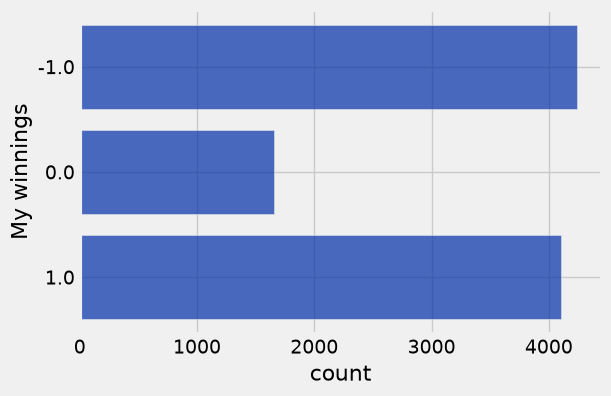

In [132]:
# datascience
results.group('My winnings').barh('My winnings')

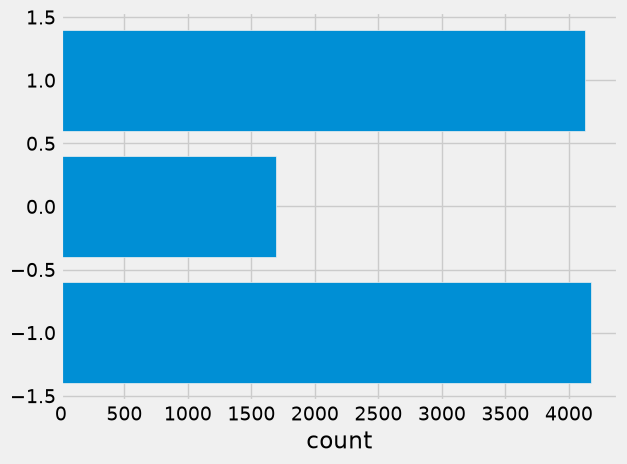

In [133]:
# polars
# matplotlib
_df = (lambda _df, _k='My winnings': _df.group_by(_k).len(name='count').sort(_k))(results_pl)
_cat = 'My winnings'
_vals = [c for c in _df.columns if c != _cat and _df[c].dtype.is_numeric()]
if len(_vals) == 1:
    plots.barh(_df.get_column(_cat).to_list(), _df.get_column(_vals[0]).to_list())
    plots.xlabel(_vals[0])
else:
    _n = len(_vals)
    _y = list(range(_df.height))
    _h = 0.8 / _n
    for _i, _c in enumerate(_vals):
        plots.barh([y + _i * _h for y in _y], _df.get_column(_c).to_list(), height=_h, label=_c)
    plots.yticks([y + _h * (_n - 1) / 2 for y in _y], _df.get_column(_cat).to_list())
    plots.legend()

In [134]:
# datascience
sum(game_outcomes)

-132.0

In [135]:
# polars
sum(game_outcomes_pl)

-47

### Another example: simulating heads in 100 coin tosses

In [136]:
# datascience
coin = make_array('heads', 'tails')

In [137]:
# polars
coin_pl = pl.Series("values", ['heads', 'tails'])

In [138]:
# datascience
sum(np.random.choice(coin, 100) == 'heads')

52

In [139]:
# polars
sum((coin_pl).sample(100, with_replacement=True) == 'heads')

51

In [140]:
# datascience
# Simulate one outcome

def num_heads():
    return sum(np.random.choice(coin, 100) == 'heads')

In [141]:
# polars
# Simulate one outcome

def num_heads_pl():
    return sum((coin_pl).sample(100, with_replacement=True) == 'heads')

In [142]:
# Decide how many times you want to repeat the experiment

repetitions = 10000

In [143]:
# datascience
# Simulate that many outcomes

outcomes = make_array()

for i in np.arange(repetitions):
    outcomes = np.append(outcomes, num_heads())

In [144]:
# polars
# Simulate that many outcomes

outcomes_pl = []

for i in pl.int_range(repetitions, eager=True):
    outcomes_pl.append(num_heads_pl())
outcomes_pl = pl.Series("values", outcomes_pl)

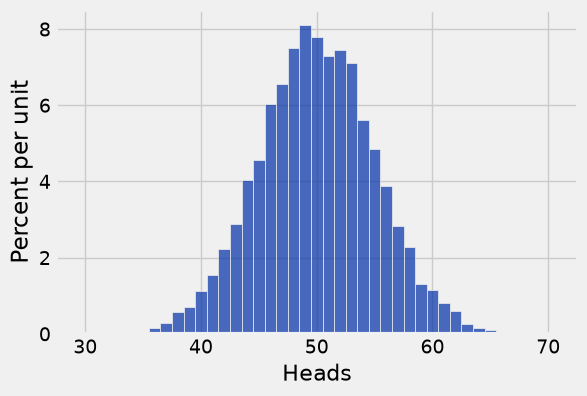

In [145]:
# datascience
heads = Table().with_column('Heads', outcomes)
heads.hist(bins = np.arange(29.5, 70.6))

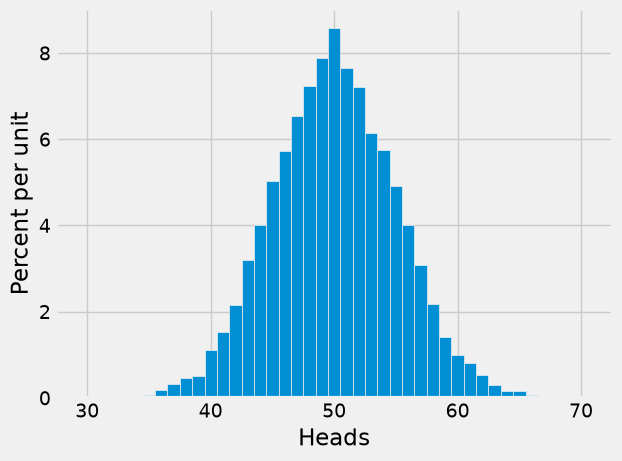

In [146]:
# polars
# matplotlib
heads_pl = pl.DataFrame({'Heads': outcomes_pl})
_df = heads_pl
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(29.5, 70.5, 42, closed="both", eager=True)))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(29.5, 70.5, 42, closed="both", eager=True)))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

## `datascience` library

In [147]:
# datascience
trip.show(3)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
901821,609,8/24/2015 0:11,Powell at Post (Union Square),71,8/24/2015 0:21,Grant Avenue at Columbus Avenue,73,611,Customer,0
901820,1063,8/23/2015 23:44,Embarcadero at Sansome,60,8/24/2015 0:02,Powell at Post (Union Square),71,383,Customer,0
901713,1550,8/23/2015 17:20,Post at Kearny,47,8/23/2015 17:45,Market at 10th,67,623,Customer,0


In [148]:
# polars
trip_pl.head(3)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
i64,i64,str,str,i64,str,str,i64,i64,str,str
912455,2092,"""8/31/2015 12:40""","""SJSU 4th at San Carlos""",12,"""8/31/2015 13:14""","""SJSU 4th at San Carlos""",12,186,"""Customer""",null
910752,586,"""8/29/2015 9:01""","""Harry Bridges Plaza (Ferry Bui…",50,"""8/29/2015 9:10""","""Powell at Post (Union Square)""",71,260,"""Customer""",null
910713,4323,"""8/29/2015 7:26""","""Embarcadero at Vallejo""",48,"""8/29/2015 8:38""","""Embarcadero at Vallejo""",48,355,"""Customer""",null


In [149]:
# datascience
trip.where('Duration', are.above(1000))
# .column('Duration')

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
901820,1063,8/23/2015 23:44,Embarcadero at Sansome,60,8/24/2015 0:02,Powell at Post (Union Square),71,383,Customer,0
901713,1550,8/23/2015 17:20,Post at Kearny,47,8/23/2015 17:45,Market at 10th,67,623,Customer,0
878924,11785,8/6/2015 16:02,Civic Center BART (7th at Market),72,8/6/2015 19:18,Embarcadero at Sansome,60,625,Customer,0
878906,12332,8/6/2015 15:52,Civic Center BART (7th at Market),72,8/6/2015 19:18,Embarcadero at Sansome,60,531,Customer,0
871652,8820,8/1/2015 12:03,Commercial at Montgomery,45,8/1/2015 14:30,Harry Bridges Plaza (Ferry Building),50,444,Customer,0
871651,8839,8/1/2015 12:02,Commercial at Montgomery,45,8/1/2015 14:29,Harry Bridges Plaza (Ferry Building),50,390,Customer,0
862514,5698,7/26/2015 16:49,Spear at Folsom,49,7/26/2015 18:24,Spear at Folsom,49,419,Customer,0
854766,6281,7/21/2015 5:13,University and Emerson,35,7/21/2015 6:58,University and Emerson,35,101,Customer,0
852559,4411,7/19/2015 11:17,Civic Center BART (7th at Market),72,7/19/2015 12:31,Market at 4th,76,877,Customer,0
805856,1194,6/13/2015 13:48,Harry Bridges Plaza (Ferry Building),50,6/13/2015 14:08,Embarcadero at Sansome,60,518,Customer,0


In [150]:
# polars
trip_pl.filter(pl.col('Duration') > 1000)
# .column('Duration')

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
i64,i64,str,str,i64,str,str,i64,i64,str,str
912455,2092,"""8/31/2015 12:40""","""SJSU 4th at San Carlos""",12,"""8/31/2015 13:14""","""SJSU 4th at San Carlos""",12,186,"""Customer""",null
910713,4323,"""8/29/2015 7:26""","""Embarcadero at Vallejo""",48,"""8/29/2015 8:38""","""Embarcadero at Vallejo""",48,355,"""Customer""",null
900971,1420,"""8/22/2015 8:56""","""Harry Bridges Plaza (Ferry Bui…",50,"""8/22/2015 9:20""","""Market at 4th""",76,193,"""Customer""",null
886240,34901,"""8/12/2015 8:57""","""Steuart at Market""",74,"""8/12/2015 18:39""","""Harry Bridges Plaza (Ferry Bui…",50,524,"""Customer""",null
881846,1115,"""8/9/2015 9:40""","""Golden Gate at Polk""",59,"""8/9/2015 9:59""","""Steuart at Market""",74,583,"""Customer""",null
…,…,…,…,…,…,…,…,…,…,…
432995,7508,"""9/1/2014 8:55""","""Powell at Post (Union Square)""",71,"""9/1/2014 11:00""","""Powell at Post (Union Square)""",71,535,"""Customer""","""nil"""
432994,7503,"""9/1/2014 8:55""","""Powell at Post (Union Square)""",71,"""9/1/2014 11:00""","""Powell at Post (Union Square)""",71,400,"""Customer""","""nil"""
432981,1536,"""9/1/2014 8:31""","""Market at 4th""",76,"""9/1/2014 8:57""","""Embarcadero at Sansome""",60,317,"""Customer""","""nil"""


In [151]:
# datascience
big_trip_durations = make_array()

In [152]:
# polars
big_trip_durations_pl = pl.Series("values", [], dtype=pl.Float64)

In [153]:
# datascience
for duration in trip.column('Duration'):
    if duration > 1000:
        big_trip_durations = np.append(big_trip_durations, duration)
np.mean(big_trip_durations)

5259.1915219611847

In [154]:
# polars
big_trip_durations_pl = list(big_trip_durations_pl)
for duration in trip_pl.get_column('Duration'):
    if duration > 1000:
        big_trip_durations_pl.append(duration)
big_trip_durations_pl = pl.Series("values", big_trip_durations_pl)
(big_trip_durations_pl).mean()

5259.191521961185

In [155]:
# datascience
np.mean(
    trip.where('Duration', are.above(1000)).column('Duration')
)

5259.1915219611847

In [156]:
# polars
(trip_pl.filter(pl.col('Duration') > 1000).get_column('Duration')).mean()

5259.191521961185

## Optional: Advanced `where` ##

In [157]:
# datascience
ages = make_array(16, 22, 18, 15, 19, 15, 16, 21)
age = Table().with_column('Age', ages)

In [158]:
# polars
ages_pl = pl.Series("values", [16, 22, 18, 15, 19, 15, 16, 21])
age_pl = pl.DataFrame({'Age': ages_pl})

In [159]:
# datascience
age

Age
16
22
18
15
19
15
16
21


In [160]:
# polars
age_pl

Age
i64
16
22
18
15
19
15
16
21


In [161]:
# datascience
age.where('Age', are.above_or_equal_to(18))

Age
22
18
19
21


In [162]:
# polars
age_pl.filter(pl.col('Age') >= 18)

Age
i64
22
18
19
21


In [163]:
# datascience
voter = ages >= 18

In [164]:
# polars
voter_pl = ages_pl >= 18

In [165]:
# datascience
voter

array([False,  True,  True, False,  True, False, False,  True], dtype=bool)

In [166]:
# polars
voter_pl

values
bool
false
true
true
false
true
false
false
true


In [167]:
# datascience
age.where(voter)

Age
22
18
19
21


In [168]:
# polars
age_pl.filter(voter_pl)

Age
i64
22
18
19
21


In [169]:
# datascience
is_voter = are.above_or_equal_to(18)

In [170]:
# polars
def is_voter_pl(x):
    return x >= 18

In [171]:
# datascience
type(is_voter)

<class 'datascience.predicates._combinable'>

In [172]:
# polars
type(is_voter_pl)

<class 'function'>

In [173]:
# datascience
is_voter(22)

True

In [174]:
# polars
is_voter_pl(22)

True

In [175]:
# datascience
is_voter(3)

False

In [176]:
# polars
is_voter_pl(3)

False

In [177]:
# datascience
age.apply(is_voter, 'Age')

array([False,  True,  True, False,  True, False, False,  True], dtype=bool)

In [178]:
# polars
age_pl.get_column('Age').map_elements(is_voter_pl, return_dtype=pl.Boolean)

<cell>:2: PolarsInefficientMapWarning: 
Series.map_elements is significantly slower than the native series API.
Only use if you absolutely CANNOT implement your logic otherwise.
Replace this expression...
  - s.map_elements(is_voter_pl)
with this one instead:
  + s >= 18



Age
bool
false
true
true
false
true
false
false
true


In [179]:
# datascience
ages >= 18

array([False,  True,  True, False,  True, False, False,  True], dtype=bool)

In [180]:
# polars
ages_pl >= 18

values
bool
false
true
true
false
true
false
false
true


In [181]:
# datascience
voter

array([False,  True,  True, False,  True, False, False,  True], dtype=bool)

In [182]:
# polars
voter_pl

values
bool
false
true
true
false
true
false
false
true


In [183]:
def my_voter_function(x):
    return x >= 18

In [184]:
# datascience
age.where('Age', are.above_or_equal_to(18))

Age
22
18
19
21


In [185]:
# polars
age_pl.filter(pl.col('Age') >= 18)

Age
i64
22
18
19
21


In [186]:
# datascience
age.where(voter)

Age
22
18
19
21


In [187]:
# polars
age_pl.filter(voter_pl)

Age
i64
22
18
19
21
